# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** Cherluk Sumdin
**Date:** 10/17/26
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

  Using cached https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All packages installed successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

- ???

In [ ]:
import pandas as pd

# Option 2: Load BBC News dataset
df = pd.read_csv('BBC News Train.csv')

# Rename columns to match the NewsBot notebook
df = df.rename(columns={
    'ArticleId': 'article_id',
    'Text': 'content',
    'Category': 'category'
})

# Add columns expected by the project
df['title'] = df['content'].str.split('.').str[0].str[:100]
df['date'] = 'Unknown'
df['source'] = 'BBC News'

# Display dataset information
print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

df.head()


Dataset loaded successfully!
Shape: (1490, 6)
Columns: ['article_id', 'content', 'category', 'title', 'date', 'source']


,article_id,content,category,title,date,source
0,1833,worldcom ex-boss launches defence lawyers defe...,business,worldcom ex-boss launches defence lawyers defe...,Unknown,BBC News
1,154,german business confidence slides german busin...,business,german business confidence slides german busin...,Unknown,BBC News
2,1101,bbc poll indicates economic gloom citizens in ...,business,bbc poll indicates economic gloom citizens in ...,Unknown,BBC News
3,1976,lifestyle governs mobile choice faster bett...,tech,lifestyle governs mobile choice faster bett...,Unknown,BBC News
4,917,enron bosses in $168m payout eighteen former e...,business,enron bosses in $168m payout eighteen former e...,Unknown,BBC News


In [ ]:
# Check the number of articles in each category
print(df['category'].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate articles
print("\nDuplicate articles:")
print(df['content'].duplicated().sum())


category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Missing values:
article_id    0
content       0
category      0
title         0
date          0
source        0
dtype: int64

Duplicate articles:
50


DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']
Date range: Unknown to Unknown
Unique sources: 1

CATEGORY DISTRIBUTION
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

News Categories


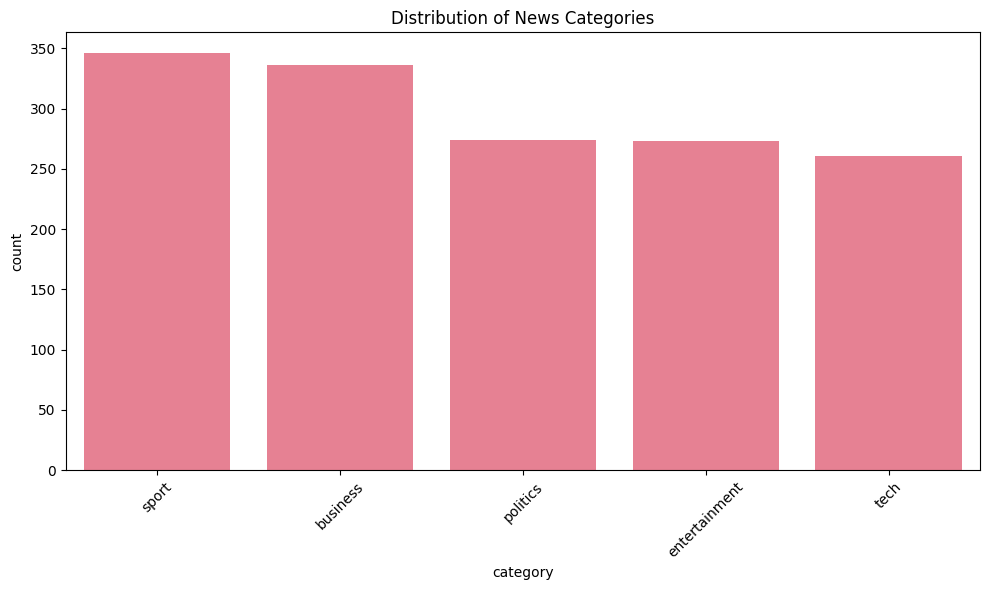


MISSING VALUES
article_id    0
content       0
category      0
title         0
date          0
source        0
dtype: int64

ARTICLE LENGTH STATISTICS
count    1490.000000
mean      385.012752
std       210.898616
min        90.000000
25%       253.000000
50%       337.000000
75%       468.750000
max      3345.000000
Name: word_count, dtype: float64

ARTICLE LENGTH DISTRIBUTION


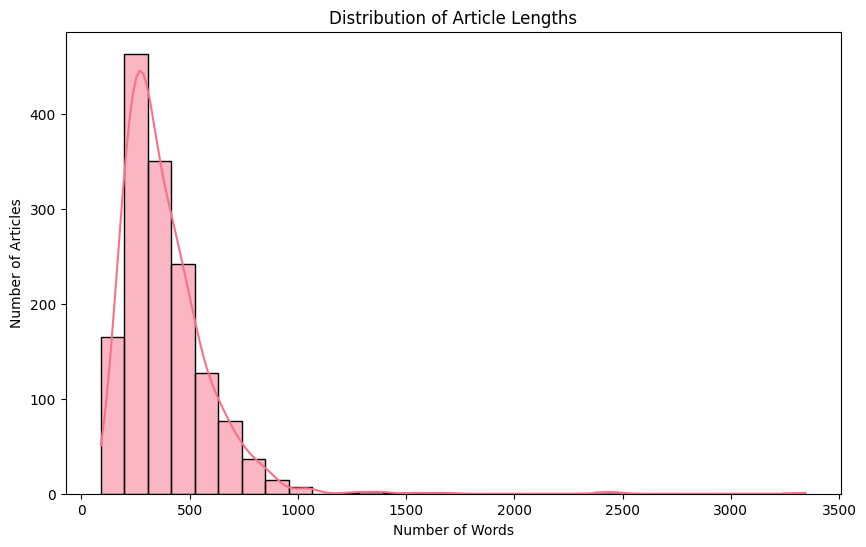


SOURCE DISTRIBUTION
source
BBC News    1490
Name: count, dtype: int64

DUPLICATE ARTICLES
Duplicate articles: 50
Empty articles: 0

Category counts:
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


In [ ]:
# Basic dataset exploration
print("DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique sources: {df['source'].nunique()}")

print("\nCATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
print("\nNews Categories")
print("=" * 50)
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#======================================================================
# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues
#======================================================================


# ================== Check for missing values ===================
print("\nMISSING VALUES")
print(df.isnull().sum())

# ======= Analyze text length distribution ======================

# Calculate article length in words
df['word_count'] = df['content'].str.split().str.len()

# Display statistics
print("\nARTICLE LENGTH STATISTICS")
print(df['word_count'].describe())

# Visualize article length
print("\nARTICLE LENGTH DISTRIBUTION")
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=30, kde=True)
plt.title('Distribution of Article Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Articles')
plt.show()


#============== examine source distribution =================
# Check source distribution
print("\nSOURCE DISTRIBUTION")
print(df['source'].value_counts())


#======== Look for any data quality issues ==================
# Check duplicate articles
print("\nDUPLICATE ARTICLES")
print("Duplicate articles:", df['content'].duplicated().sum())

# Check empty articles
print("Empty articles:",
      df['content'].fillna('').str.strip().eq('').sum())

# Check category distribution
print("\nCategory counts:")
print(df['category'].value_counts())

I explored the BBC News dataset to understand the data before preprocessing. I checked for missing values, analyzed article lengths, examined the source distribution, and looked for data quality issues.

The dataset contains 1,490 articles across 5 categories, including business, technology, politics, sports, and entertainment. I found 0 missing values and 50 duplicate articles. The average article length was approximately 385 words. The shortest article had 90 words, while the longest had 3,345 words. I also noticed that the article lengths varied, but most articles were between 253 and 469 words. The sport category had the most articles with 346, while the tech category had the fewest with 261.

All articles were labeled as BBC News because the dataset did not provide individual source information. Overall, I believe the dataset is suitable for this project because there are no missing values or empty articles, and the categories are fairly balanced. However, I would need to remove the duplicate articles before training the machine learning models to avoid affecting the results.

In [ ]:
# Remove duplicate articles
df = df.drop_duplicates(subset=['content']).copy()

# Reset the index
df = df.reset_index(drop=True)

# Check the dataset after removing duplicates
print("Total articles after cleaning:", len(df))
print("Remaining duplicates:", df['content'].duplicated().sum())

Total articles after cleaning: 1440
Remaining duplicates: 0


## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create new columns for processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers worldcom exboss ...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope german busin...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service bbc poll indica...


In [ ]:
#compare before and after word count
before = df['full_text'].str.split().str.len()
after = df['full_text_processed'].str.split().str.len()

print("Average words before:", round(before.mean(), 2))
print("Average words after:", round(after.mean(), 2))
print("Reduction:", round((1 - after.mean() / before.mean()) * 100, 2), "%")

#count unique words
original_words = set(' '.join(df['full_text'].str.lower()).split())
processed_words = set(' '.join(df['full_text_processed']).split())

print("\nUnique words before:", len(original_words))
print("Unique words after:", len(processed_words))

#find the most common words
from collections import Counter

all_words = ' '.join(df['full_text_processed']).split()

word_counts = Counter(all_words)

print("\nTop 20 most common words:")
for word, count in word_counts.most_common(20):
    print(word, count)

Average words before: 402.2
Average words after: 218.19
Reduction: 45.75 %

Unique words before: 35993
Unique words after: 22812

Top 20 most common words:
said 4735
year 1864
would 1668
new 1405
also 1366
people 1274
one 1183
could 1048
game 957
time 926
first 886
last 877
say 849
world 832
film 830
two 827
government 788
firm 709
company 690
make 685


I applied text preprocessing to the BBC News dataset using Python and NLTK. The preprocessing included converting text to lowercase, removing URLs and punctuation, tokenization, stop-word removal, and lemmatization.

Before preprocessing, the average article length was 402.2 words. After preprocessing, it decreased to 218.19 words, which is a 45.75% reduction. The number of unique words also decreased from 35,993 to 22,812. This shows that preprocessing removed many unnecessary words and reduced different forms of words to a more consistent format.

I also analyzed the most common words after preprocessing. The most frequent word was "said," appearing 4,735 times, followed by words such as "year," "would," and "new." I noticed that some words, such as "game," "film," and "government," could help identify different news categories.


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1440, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


In [ ]:
# Get TF-IDF scores for the first article
feature_names = tfidf_vectorizer.get_feature_names_out()

scores = pd.Series(
    tfidf_matrix[0].toarray().flatten(),
    index=feature_names
)

# Display the 10 highest TF-IDF scores
print(scores.nlargest(10))

worldcom           0.582931
ebbers             0.388007
accounting         0.339790
cooper             0.214948
former worldcom    0.169223
fraud              0.167552
lawyer             0.161215
mci                0.109089
auditor            0.107474
chief              0.105119
dtype: float64


- Converted 1,440 articles into 5,000 numerical TF-IDF features.
- Learned that 97.5% of the matrix values are zero, which is normal for text data.
- Examined the highest-scoring terms in an individual article.
- Confirmed that those terms relate closely to the article's topic.

The important lesson: TF-IDF helps us identify words that are distinctive within an article, rather than simply selecting the most frequently used words.

In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0384
  company: 0.0341
  bank: 0.0328
  share: 0.0321
  growth: 0.0318
  market: 0.0316
  economy: 0.0309
  sale: 0.0306
  year: 0.0303
  profit: 0.0278

📰 TECH:
  mobile: 0.0525
  phone: 0.0482
  people: 0.0442
  technology: 0.0396
  game: 0.0390
  user: 0.0369
  software: 0.0349
  net: 0.0344
  service: 0.0340
  computer: 0.0330

📰 POLITICS:
  labour: 0.0644
  blair: 0.0597
  election: 0.0573
  party: 0.0506
  tory: 0.0474
  government: 0.0430
  would: 0.0423
  minister: 0.0417
  brown: 0.0403
  tax: 0.0326

📰 SPORT:
  game: 0.0400
  england: 0.0377
  win: 0.0311
  player: 0.0288
  champion: 0.0274
  cup: 0.0273
  match: 0.0270
  chelsea: 0.0252
  coach: 0.0235
  wale: 0.0231

📰 ENTERTAINMENT:
  film: 0.0967
  award: 0.0505
  best: 0.0422
  star: 0.0401
  show: 0.0371
  music: 0.0355
  actor: 0.0341
  band: 0.0315
  oscar: 0.0282
  year: 0.0271


Category TF-IDF results ready!


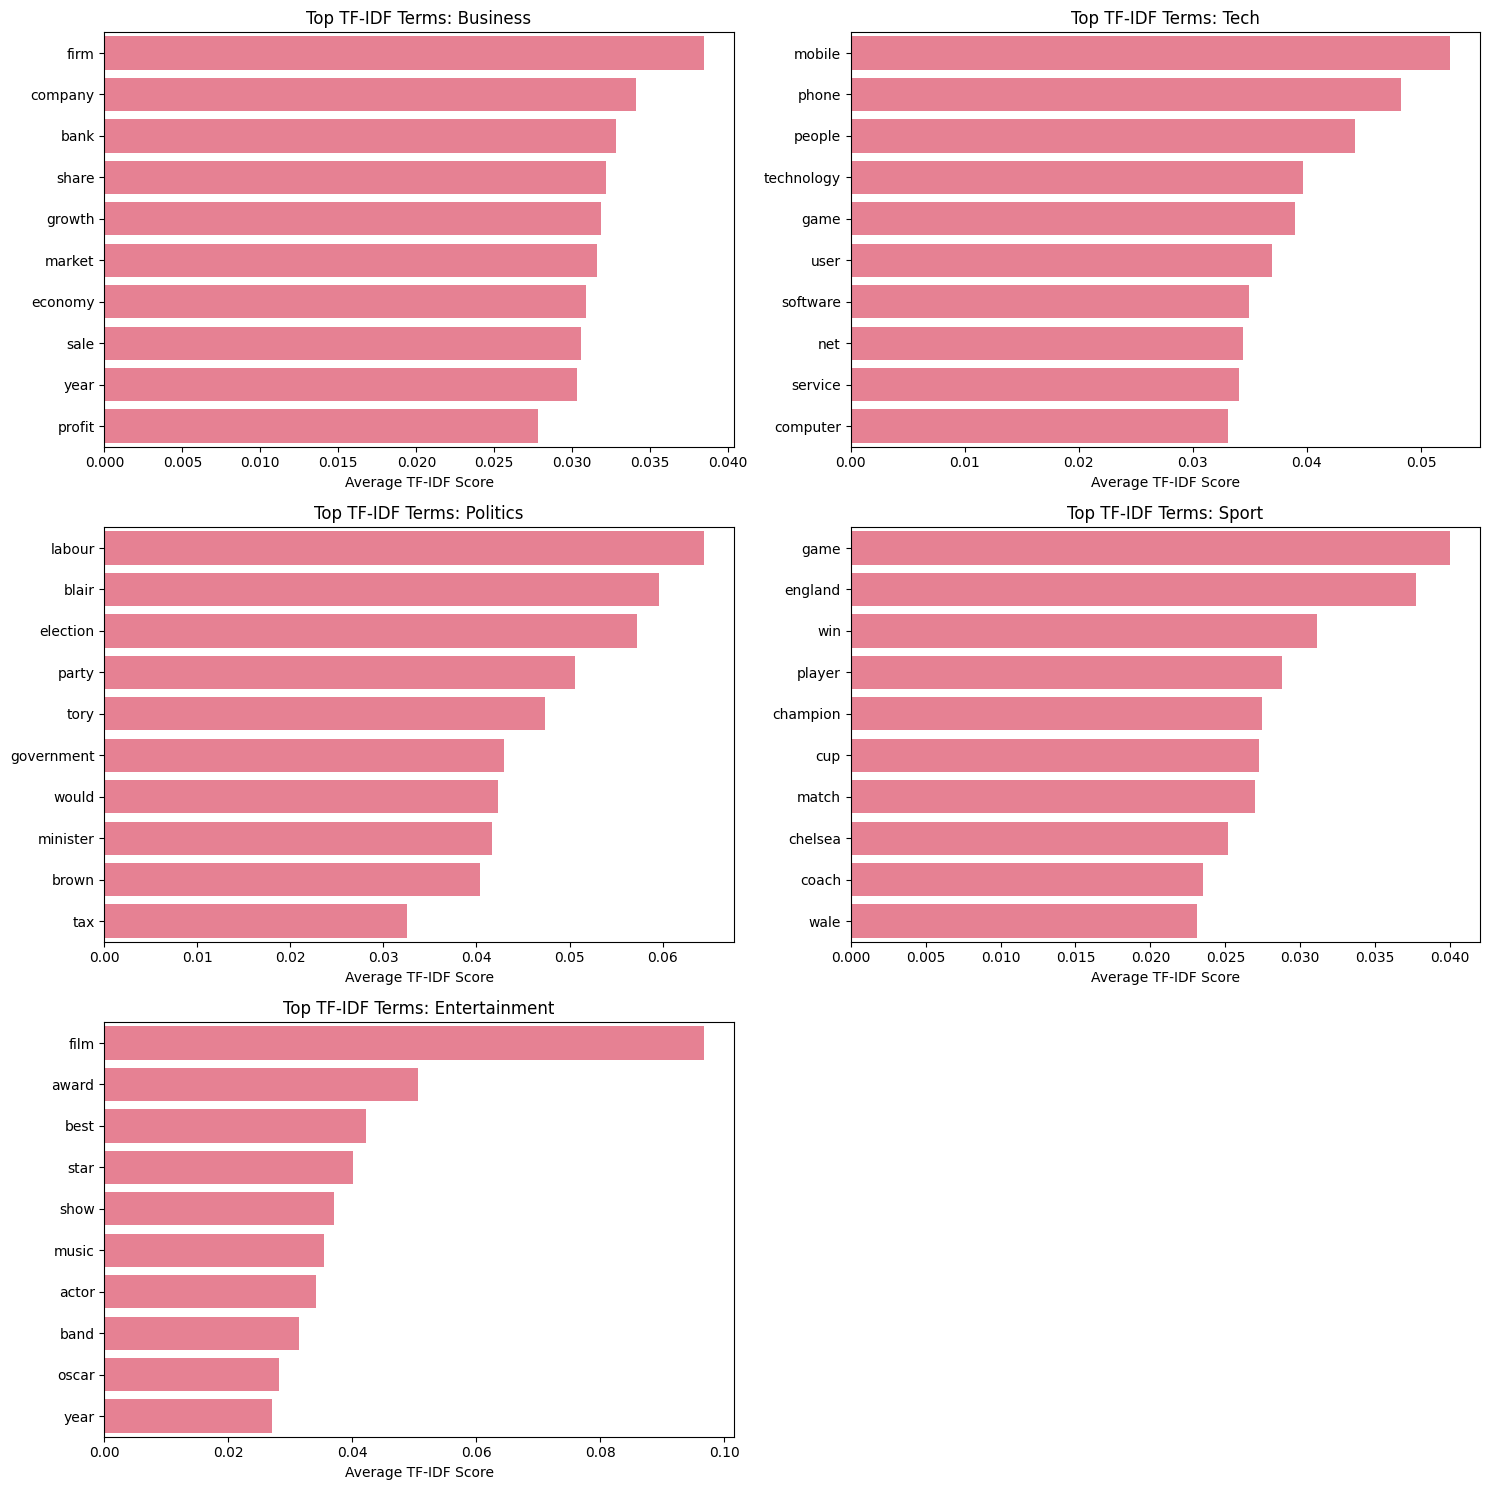

In [ ]:
import numpy as np

feature_names = tfidf_vectorizer.get_feature_names_out()

category_top_terms = {}

for category in df['category'].unique():
    # Select articles belonging to this category
    mask = (df['category'] == category).to_numpy()

    # Calculate average TF-IDF scores
    avg_scores = np.asarray(
        tfidf_matrix[mask].mean(axis=0)
    ).flatten()

    # Find the top 10 terms
    top_indices = avg_scores.argsort()[-10:][::-1]

    category_top_terms[category] = [
        (feature_names[i], float(avg_scores[i]))
        for i in top_indices
    ]

print("Category TF-IDF results ready!")

# Visualize top 10 TF-IDF terms for each category

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, (category, terms) in enumerate(category_top_terms.items()):
    words = [word for word, score in terms[:10]]
    scores = [score for word, score in terms[:10]]

    sns.barplot(
        x=scores,
        y=words,
        ax=axes[i]
    )

    axes[i].set_title(f'Top TF-IDF Terms: {category.title()}')
    axes[i].set_xlabel('Average TF-IDF Score')
    axes[i].set_ylabel('')

# Hide unused subplot
for j in range(len(category_top_terms), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

##Mod 03 - Analysis

In Module 3, I learned how to use TF-IDF (Term Frequency–Inverse Document Frequency) to identify important words and phrases in news articles. I used the cleaned text from Module 2 and converted 1,440 articles into a TF-IDF matrix with 5,000 features. The matrix had a sparsity of 97.50%, which means most of the values were zero because not every word appeared in every article.

I also analyzed the highest TF-IDF scores for individual articles and different news categories. For example, the first article had high scores for words such as "worldcom," "ebbers," "accounting," and "fraud," which helped identify its main topic. When comparing news categories, I found that Business had important words such as "firm," "company," and "bank," while Technology had "mobile," "phone," and "software." Politics had words such as "labour," "blair," and "election," while Sport had "game," "england," and "player." Entertainment had "film," "award," and "music."

One interesting thing I noticed was that some words appeared in multiple categories. For example, "game" appeared in both Technology and Sport because it could refer to video games or sporting events. I learned that TF-IDF helps identify important words, but it does not fully understand the meaning or context of an article. Overall, this module helped me understand how text can be converted into numerical features that machine learning models can use to classify news articles.

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.093939  0.118182  0.236364  0.027273  0.109091  0.066667  0.015152   
1  0.128852  0.070028  0.235294  0.033613  0.134454  0.081232  0.014006   
2  0.080214  0.080214  0.204991  0.024955  0.121212  0.096257  0.016043   
3  0.084548  0.106414  0.155977  0.023324  0.119534  0.061224  0.040816   
4  0.089552  0.079602  0.216418  0.027363  0.119403  0.099502  0.017413   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.039394  0.012121  0.036364  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.028011  0.005602  0.039216  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.030303  0.016043  0.039216  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017493  0.013120  0.045190  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.027363  0.014925  0.039801  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2275  0.0746  0.0011  0.0000  0.0333  0.0399  0.0199  0.0283   
entertainment  0.2507  0.0581  0.0008  0.0000  0.0285  0.0447  0.0189  0.0304   
politics       0.2117  0.0690  0.0007  0.0003  0.0459  0.0450  0.0209  0.0306   
sport          0.2245  0.0489  0.0005  0.0000  0.0407  0.0448  0.0174  0.0255   
tech           0.1951  0.0856  0.0007  0.0000  0.0420  0.0290  0.0240  0.0267   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0166  0.0252  0.0942  0.0045  0.0034  0.0268  0.0017  0.0006   
entertainment  0.0192  0.0240  0.0954  0.0024  0.0050  0.0274  0.0009  0.0010   
politics       0.0205  0.0234  0.0913  0.0032  0

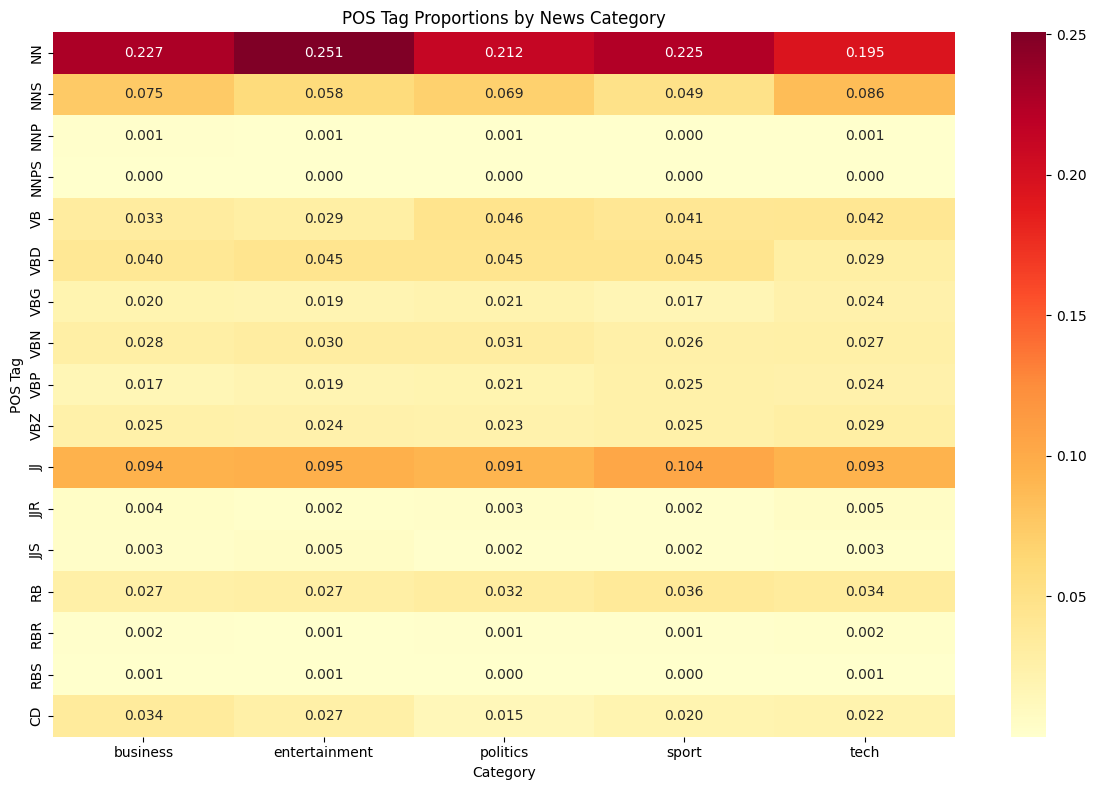


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## Mod 05 - Analyze
1. Business with 0.001

2. Politic with VB 0.0459, VBD 0.0450, VBG 0.0209.

3. Sport has the highest at 0.1037, while Politics has the lowest at 0.0913. This could be because sports articles use descriptive words when discussing players, teams, and performances.

4. Business has the highest proportion of numbers at 0.0343, entertainment at 0.0268. Politics has the lowest at 0.0145. Business articles often include financial figures, prices, percentages, and economic statistics.


 I used POS tagging to analyze the grammatical patterns in different news categories. The results showed that Business had the highest proportion of proper nouns at 0.11%, while Politics had the highest combined proportion of action verbs at 11.18%. I also found that Sport had the highest proportion of adjectives at 10.37%, which could be because sports articles often use descriptive words when discussing players, teams, and performances. Another interesting finding was that Business had the highest proportion of numbers at 3.43%, which makes sense because business articles often include financial information, prices, and statistics.

One thing I noticed was that the proportion of proper nouns was very low across all categories. This could mean that the POS tagger did not recognize some names correctly.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 362
  Noun phrases: ['worldcom ex', '-', 'boss']...
  Subjects: ['ex', '-', 'boss']...
  Objects: ['lawyers', 'ebbers', 'ex']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 383
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'confidence', 'ifo']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 605
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'citizens']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 743
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'lifestyle']...
  Objects: ['choice', 'hardware', 'choice']...

📰 Article 5 (business):
  Sentences: 17
  To

In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b

In [ ]:
# Task 1: Compare syntactic complexity across categories

# Sample 10 articles from each category
sample_df = df.groupby('category').sample(n=10, random_state=42)

complexity_results = []

for idx, row in sample_df.iterrows():
    features = extract_syntactic_features(row['full_text'])

    complexity_results.append({
        'category': row['category'],
        'avg_sentence_length': features['num_tokens'] / max(features['num_sentences'], 1),
        'num_noun_phrases': len(features['noun_phrases'])
    })

# Convert results into a DataFrame
complexity_df = pd.DataFrame(complexity_results)

# Compare category averages
complexity_summary = complexity_df.groupby('category').mean()

print("Syntactic Complexity by Category:")
print(complexity_summary.round(2))

Syntactic Complexity by Category:
               avg_sentence_length  num_noun_phrases
category                                            
business                     26.64              85.3
entertainment                26.24              88.0
politics                     26.90             107.5
sport                        23.30              87.4
tech                         24.53             147.6


The results showed that Politics had the longest average sentence length at 26.90 tokens, while Sport had the shortest at 23.30 tokens. Tech had the highest average number of noun phrases at 147.6 per article. I noticed that different news categories have different sentence structures. However, longer articles may contain more noun phrases, so the number of noun phrases does not always mean the sentences are more complex.

In [ ]:
# Task 2: Extract subject-verb-object (SVO) patterns

def extract_action_patterns(text):
    doc = nlp(str(text))
    patterns = []

    for token in doc:
        # Find verbs
        if token.pos_ == 'VERB':

            # Find subjects connected to the verb
            subjects = [
                child.text for child in token.children
                if child.dep_ in ['nsubj', 'nsubjpass']
            ]

            # Find objects connected to the verb
            objects = [
                child.text for child in token.children
                if child.dep_ in ['dobj', 'obj', 'iobj']
            ]

            # Save patterns with both subject and object
            for subject in subjects:
                for obj in objects:
                    patterns.append((subject, token.text, obj))

    return patterns


# Analyze the first 5 articles
for idx, row in df.head(5).iterrows():
    patterns = extract_action_patterns(row['content'])

    print(f"\nArticle {idx+1} ({row['category']}):")

    if patterns:
        for subject, verb, obj in patterns[:5]:
            print(f"  {subject} → {verb} → {obj}")
    else:
        print("  No complete action patterns found.")


Article 1 (business):
  - → launches → lawyers
  boss → launches → lawyers
  s → alerted → directors
  ebbers → orchestrated → series
  who → runs → business

Article 2 (business):
  confidence → slides → confidence
  economy → called → dip
  he → expected → upswing
  exports → kept → things
  figures → delay → rise

Article 3 (business):
  they → experiencing → effects
  china → seen → decades
  results → reflect → confidence
  pipa → conducted → poll
  interviews → took → place

Article 4 (tech):
  lifestyle → governs → choice
  lifestyle → governs → hardware
  firms → sell → research
  chip → shows → study
  michael → bjorn → advisor

Article 5 (business):
  directors → agreed → m
  10 → pay → m
  it → hidden → millions
  demise → sent → shockwaves
  none → admit → wrongdoing


The results showed that the model could identify action patterns such as "ebbers → orchestrated → series" and "pipa → conducted → poll." However, I also noticed some incorrect patterns, such as "- → launches → lawyers" and "michael → bjorn → advisor." These errors showed me that dependency parsing is not always accurate, especially when the text contains names, punctuation, or complicated sentences. I learned that extracting action patterns can help us understand what is happening in an article, but the results may still need to be reviewed

In [ ]:
# Task 3: Find the most common dependency relations per category

# Reuse the 50 articles sampled in Task 1
dependency_results = {}

for category, group in sample_df.groupby('category'):
    all_dependencies = Counter()

    for idx, row in group.iterrows():
        features = extract_syntactic_features(row['full_text'])

        # Count dependency relations
        all_dependencies.update(features['dependency_counts'])

    # Save the top 5 dependency relations
    dependency_results[category] = all_dependencies.most_common(5)

# Display results
for category, relations in dependency_results.items():
    print(f"\n{category.upper()} - Top 5 Dependency Relations:")

    for dep, count in relations:
        print(f"  {dep}: {count}")


BUSINESS - Top 5 Dependency Relations:
  prep: 372
  pobj: 359
  det: 341
  amod: 284
  compound: 270

ENTERTAINMENT - Top 5 Dependency Relations:
  prep: 383
  pobj: 371
  det: 335
  nsubj: 280
  compound: 276

POLITICS - Top 5 Dependency Relations:
  prep: 440
  pobj: 427
  det: 411
  compound: 394
  nsubj: 340

SPORT - Top 5 Dependency Relations:
  prep: 332
  nsubj: 320
  pobj: 310
  det: 278
  compound: 269

TECH - Top 5 Dependency Relations:
  prep: 610
  pobj: 586
  det: 528
  nsubj: 461
  amod: 419


I used spaCy to identify the most common dependency relations across five news categories. I analyzed 10 articles from each category and found that "prep" was the most common dependency relation in every category. Other common relations included "pobj" and "det." I also noticed that "nsubj" appeared in the top five for most categories except Business, while "amod" appeared in Business and Tech. Tech had the highest number of dependency relations, but this could be because the sampled articles were longer.

In [ ]:
# Task 4: Create syntactic features for classification

syntax_features = []

for idx, row in sample_df.iterrows():
    features = extract_syntactic_features(row['full_text'])
    dep_counts = features['dependency_counts']

    syntax_features.append({
        'article_id': row['article_id'],
        'category': row['category'],

        # Sentence structure
        'num_sentences': features['num_sentences'],
        'avg_sentence_length': features['num_tokens'] / max(features['num_sentences'], 1),

        # Noun phrases, subjects, and objects
        'num_noun_phrases': len(features['noun_phrases']),
        'num_subjects': len(features['subjects']),
        'num_objects': len(features['objects']),

        # Dependency relations
        'num_nsubj': dep_counts.get('nsubj', 0),
        'num_dobj': dep_counts.get('dobj', 0),
        'num_prep': dep_counts.get('prep', 0),
        'num_amod': dep_counts.get('amod', 0)
    })

# Convert to DataFrame
syntax_features_df = pd.DataFrame(syntax_features)

print("Syntactic Features for Classification:")
print(syntax_features_df.head())

print("\nDataset Shape:", syntax_features_df.shape)

Syntactic Features for Classification:
   article_id  category  num_sentences  avg_sentence_length  num_noun_phrases  \
0        2048  business             12            28.166667                68   
1        1749  business             12            27.250000                76   
2        2199  business             15            27.466667                98   
3        2185  business             19            25.842105               119   
4        1376  business             12            30.250000                73   

   num_subjects  num_objects  num_nsubj  num_dobj  num_prep  num_amod  
0            22           46         20        13        34        19  
1            21           50         18        14        38        18  
2            32           63         32        25        40        34  
3            38           77         30        22        60        37  
4            29           42         24         8        35        35  

Dataset Shape: (50, 11)


I created numerical features based on the syntactic structure of news articles. I used 50 articles, with 10 articles from each category, and extracted nine features, including sentence length, noun phrases, subjects, objects, and dependency relations. The results were stored in a DataFrame with 50 rows and 11 columns. I learned that syntactic information can be converted into numerical values that machine learning models could use for classification. However, some features depend on article length, so they may need to be normalized before training a model.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1440 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  business         -0.9694   negative
1  business          0.8948   positive
2  business         -0.9454   negative
3      tech          0.9542   positive
4  business         -0.9383   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2279  0.8463 -0.9985  0.9995    0.0922    0.8371   
entertainment         0.5765  0.7090 -0.9978  0.9999    0.1361    0.8089   
politics              0.0359  0.8847 -0.9985  0.9999    0.0939    0.8187   
sport                 0.5453  0.7391 -0.9970  0.9996    0.1335    0.7954   
tech                  0.5225  0.7593 -0.9992  0.9993    0.0896    0.8598   

              neg_score  
                   mean  
category                 
business         0.0707  
entertainment    0.0550  
politics         0.0874  
sport            0.0711  
tech             0.0506  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

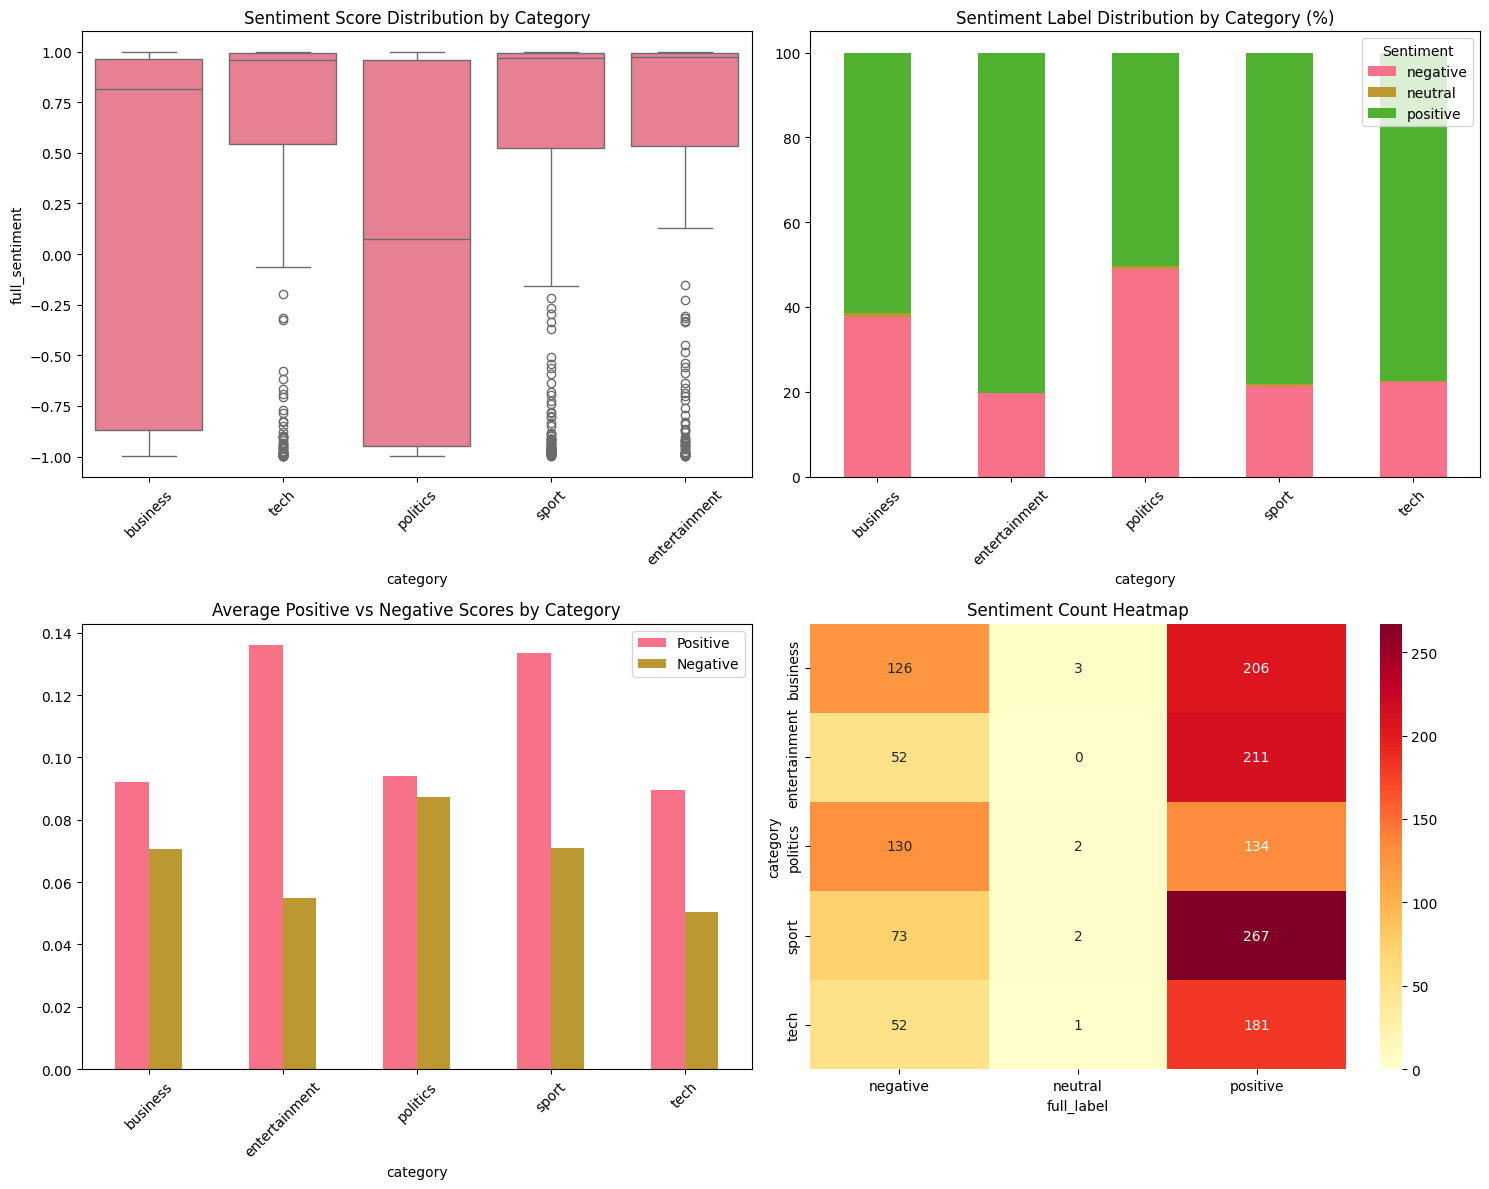

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

In [ ]:
# Compare average title and content sentiment by category
title_content_comparison = sentiment_df.groupby('category')[
    ['title_sentiment', 'content_sentiment']
].mean()

print(title_content_comparison.round(4))

               title_sentiment  content_sentiment
category                                         
business                0.0217             0.2381
entertainment           0.1747             0.5900
politics               -0.0748             0.0541
sport                   0.0647             0.5492
tech                    0.0794             0.5330


# Which categories are most positive/negative?
  - Entertain are the most positive and politic are the most negative.

# Are there differences between title and content sentiment?
  - Yes, the results showed that article content had higher average sentiment scores than titles in all five news categories. The content sentiment has higher score because titles are usually shorter and provide less information, while content contains more details and emotional words that can affect the overall sentiment score.

# How does sentiment vary within categories?
  - Sentiment varies within each news category because there is a mix of positive and negative articles. Politics had the highest sentiment variation, meaning its articles had a wider range of positive and negative scores. Entertainment had the lowest variation, meaning its articles had more similar sentiment scores

# Can sentiment be used as a feature for classification?
  - Yes, sentiment can be used as a feature for classification because it provides numerical scores that a machine learning model can use to identify patterns in news articles.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
# sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values.copy()

# Convert compound sentiment from [-1, 1] to [0, 1]
sentiment_features[:, 0] = (sentiment_features[:, 0] + 1) / 2

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1440, 5007)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1152 samples
  Test set: 288 samples


In [ ]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.6354
  📊 CV Score: 0.5425 (+/- 0.0590)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.6562
  📊 CV Score: 0.7101 (+/- 0.0998)

🔄 Training SVM...
  ✅ Accuracy: 0.3924
  📊 CV Score: 0.3472 (+/- 0.0381)

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.6354   0.5425  0.0295
1  Logistic Regression         0.6562   0.7101  0.0499
2                  SVM         0.3924   0.3472  0.0191

🥇 Best performing model: Logistic Regression


📊 DETAILED EVALUATION: Logistic Regression

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.90      0.64      0.75        67
entertainment       0.86      0.83      0.85        53
     politics       0.35      0.53      0.42        53
        sport       0.71      0.75      0.73        68
         tech       0.62      0.49      0.55        47

     accuracy                           0.66       288
    macro avg       0.69      0.65      0.66       288
 weighted avg       0.70      0.66      0.67       288



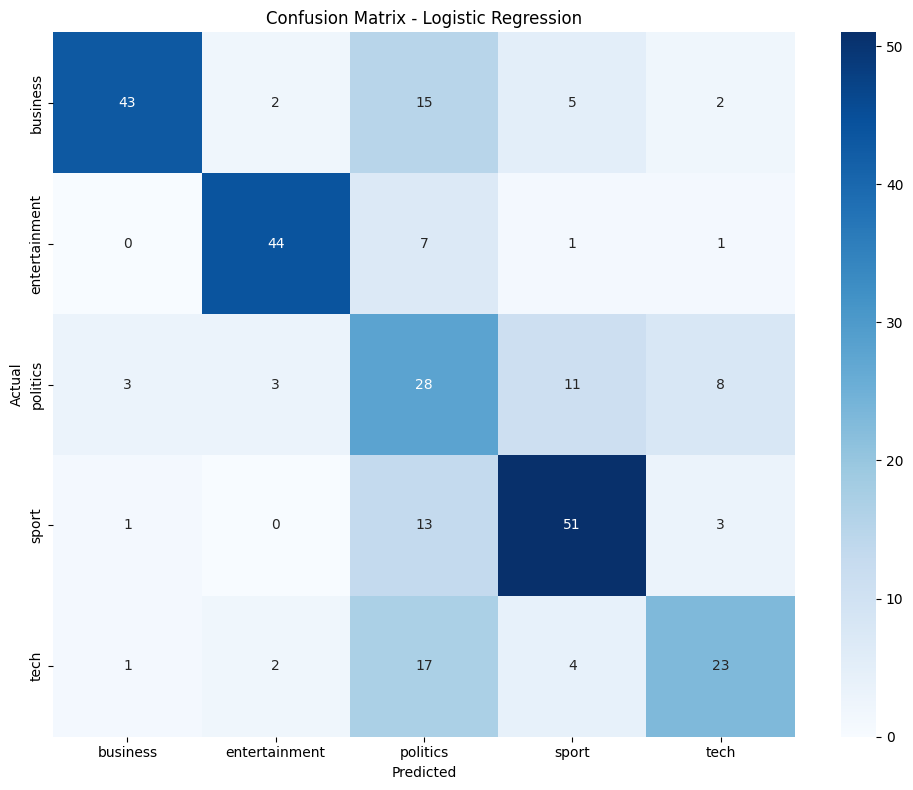


🔍 Top Features by Category:

📰 business:
  neu_score: 1.0656
  bank: 0.9618
  firm: 0.8397
  economy: 0.8309
  growth: 0.7980
  share: 0.7956
  rate: 0.7622
  market: 0.7471
  oil: 0.7307
  company: 0.7273

📰 entertainment:
  film: 2.4626
  sentiment: 1.6134
  award: 1.1314
  star: 0.8923
  best: 0.8469
  show: 0.8142
  actor: 0.7998
  oscar: 0.7419
  band: 0.6942
  music: 0.6750

📰 politics:
  labour: 1.5195
  blair: 1.4029
  election: 1.3098
  party: 1.1572
  tory: 1.1541
  brown: 0.9179
  minister: 0.9048
  government: 0.8084
  lord: 0.6710
  would: 0.6600

📰 sport:
  sentiment: 1.1170
  england: 1.0015
  game: 0.7901
  chelsea: 0.7452
  cup: 0.7265
  match: 0.7116
  pos_score: 0.6946
  champion: 0.6782
  coach: 0.6654
  player: 0.6506

📰 tech:
  sentiment: 2.4527
  mobile: 1.1753
  phone: 1.0822
  technology: 0.7779
  user: 0.7702
  neu_score: 0.7217
  broadband: 0.7093
  microsoft: 0.7085
  software: 0.6620
  people: 0.6076


In [ ]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

# Improve the classifier
 - Try different feature combinations
 - Experiment with hyperparameter tuning
 - Add more sophisticated features
 - Handle class imbalance if present

In [ ]:
# Step 1: Compare different feature combinations

from sklearn.preprocessing import StandardScaler

# Use the same training/test split as before
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=42, stratify=y
)

# Scale text length features so large values don't dominate
scaler = StandardScaler()
length_scaled = np.zeros_like(length_features, dtype=float)
length_scaled[train_idx] = scaler.fit_transform(length_features[train_idx])
length_scaled[test_idx] = scaler.transform(length_features[test_idx])

# Create feature combinations
feature_sets = {
    'TF-IDF Only': X_tfidf,
    'TF-IDF + Sentiment': np.hstack([X_tfidf, sentiment_features]),
    'TF-IDF + Sentiment + Scaled Length': np.hstack([
        X_tfidf, sentiment_features, length_scaled
    ])
}

# Train and compare
feature_results = {}

for name, X_features in feature_sets.items():
    model = LogisticRegression(random_state=42, max_iter=1000)

    model.fit(X_features[train_idx], y[train_idx])
    predictions = model.predict(X_features[test_idx])

    accuracy = accuracy_score(y[test_idx], predictions)
    feature_results[name] = accuracy

    print(f"{name}: {accuracy:.4f}")

print(f"\nOriginal Combined Accuracy: {results['Logistic Regression']['accuracy']:.4f}")

TF-IDF Only: 0.9583
TF-IDF + Sentiment: 0.9340
TF-IDF + Sentiment + Scaled Length: 0.9236

Original Combined Accuracy: 0.6562


I tested three different feature combinations to see which one would improve the classifier. TF-IDF alone performed the best with an accuracy of 95.83%, compared to the original model's accuracy of 65.62%. Adding sentiment and text length features did not improve the results. This showed that adding more features does not always make a machine learning model more accurate.

In [ ]:
# Step 2: Hyperparameter tuning

from sklearn.model_selection import GridSearchCV

# Use TF-IDF only (best feature combination)
X_train_tfidf = X_tfidf[train_idx]

# Test different C values
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_tfidf, y[train_idx])

print("Best C:", grid_search.best_params_['C'])
print("Best CV Accuracy:", round(grid_search.best_score_, 4))

Best C: 100
Best CV Accuracy: 0.9696


After testing different C values, I found that C = 100 gave the best result for Logistic Regression, with a cross-validation accuracy of 96.96%. This means the model correctly classified about 97% of the validation articles on average. Hyperparameter tuning helps improve the classifier by finding the best settings instead of using the default values. However, I still need to test the tuned model to confirm whether its accuracy improved.

In [ ]:
# Evaluate the tuned Logistic Regression model

tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_tfidf[test_idx])

tuned_accuracy = accuracy_score(y[test_idx], tuned_predictions)

print(f"Original TF-IDF Accuracy: {feature_results['TF-IDF Only']:.4f}")
print(f"Tuned Model Accuracy: {tuned_accuracy:.4f}")
print(f"Best C Value: {grid_search.best_params_['C']}")

Original TF-IDF Accuracy: 0.9583
Tuned Model Accuracy: 0.9722
Best C Value: 100


After hyperparameter tuning, I found that C = 100 gave the best results for Logistic Regression. The model's test accuracy increased from 95.83% to 97.22%. This showed that adjusting the model's settings can improve classification performance without changing the features.

In [ ]:
# Step 3: Add More Sophisticated Features (POS Tagging)

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Define five POS feature groups
pos_groups = {
    'nouns': ['NN', 'NNS'],
    'proper_nouns': ['NNP', 'NNPS'],
    'verbs': ['VB', 'VBD', 'VBG'],
    'adjectives': ['JJ'],
    'numbers': ['CD']
}

# 2. Match POS data with the correct articles
pos_aligned = df[['article_id']].merge(
    pos_df,
    on='article_id',
    how='left',
    validate='one_to_one'
)

# 3. Extract POS features
pos_data = pd.DataFrame(index=df.index)

for name, tags in pos_groups.items():
    pos_data[name] = pos_aligned[tags].sum(axis=1)

# 4. Scale POS features
pos_scaler = StandardScaler()

X_pos_train = pos_scaler.fit_transform(pos_data.iloc[train_idx])
X_pos_test = pos_scaler.transform(pos_data.iloc[test_idx])

# 5. Combine TF-IDF with POS features
X_train_advanced = np.hstack([
    X_tfidf[train_idx],
    X_pos_train
])

X_test_advanced = np.hstack([
    X_tfidf[test_idx],
    X_pos_test
])

# 6. Train Logistic Regression with best C value
advanced_model = LogisticRegression(
    C=100,
    random_state=42,
    max_iter=1000
)

advanced_model.fit(X_train_advanced, y[train_idx])

# 7. Evaluate the model
advanced_predictions = advanced_model.predict(X_test_advanced)
advanced_accuracy = accuracy_score(y[test_idx], advanced_predictions)

# 8. Compare results
print("TF-IDF Only Accuracy:", round(tuned_accuracy, 4))
print("TF-IDF + POS Accuracy:", round(advanced_accuracy, 4))
print("Difference:", round(advanced_accuracy - tuned_accuracy, 4))

TF-IDF Only Accuracy: 0.9722
TF-IDF + POS Accuracy: 0.9653
Difference: -0.0069


In this experiment, I added POS tagging features such as nouns, verbs, adjectives, proper nouns, and numbers to my TF-IDF model. After training the model, the accuracy decreased from 97.22% to 96.53%. This showed me that adding more features does not always improve the model's performance. Based on these results, I would keep the TF-IDF-only model because it performed better.

In [ ]:
# Step 4: Check for Class Imbalance

# Count articles in each category
class_counts = df['category'].value_counts()

# Calculate percentage of each category
class_percentages = df['category'].value_counts(normalize=True) * 100

# Display results
class_distribution = pd.DataFrame({
    'Article Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})

print(class_distribution)

# Compare largest and smallest categories
imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance Ratio:", round(imbalance_ratio, 2))

               Article Count  Percentage (%)
category                                    
sport                    342           23.75
business                 335           23.26
politics                 266           18.47
entertainment            263           18.26
tech                     234           16.25

Imbalance Ratio: 1.46


The result shows that the classes are slightly imbalance. Class imbalance is not just about having different numbers of articles. It becomes a problem when those differences cause the model to perform poorly on certain categories. I  don't think it needs to fix the imbalance because the difference between the categories is relatively small, and the model already has a high accuracy of 97.22%

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 43215
📰 Articles processed: 1440

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8758
PERSON         8408
CARDINAL       6266
GPE            5889
ORG            4602
NORP           2934
MONEY          1788
ORDINAL        1668
PERCENT        1272
TIME            595
LOC             517
QUANTITY        194
FAC              97
PRODUCT          92
LANGUAGE         50
EVENT            43
LAW              33
WORK_OF_ART       9
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1104  2478      4   11  1716         1   15  178    958   
entertainment      1116  1713     11   16   832         9    4   65    352   
politics            847  1339     22   27   989        10    4  126    231   
sport              1880  2030      5   42  1615        11    5   36     46   
tech               1319  1198      1    1   737     

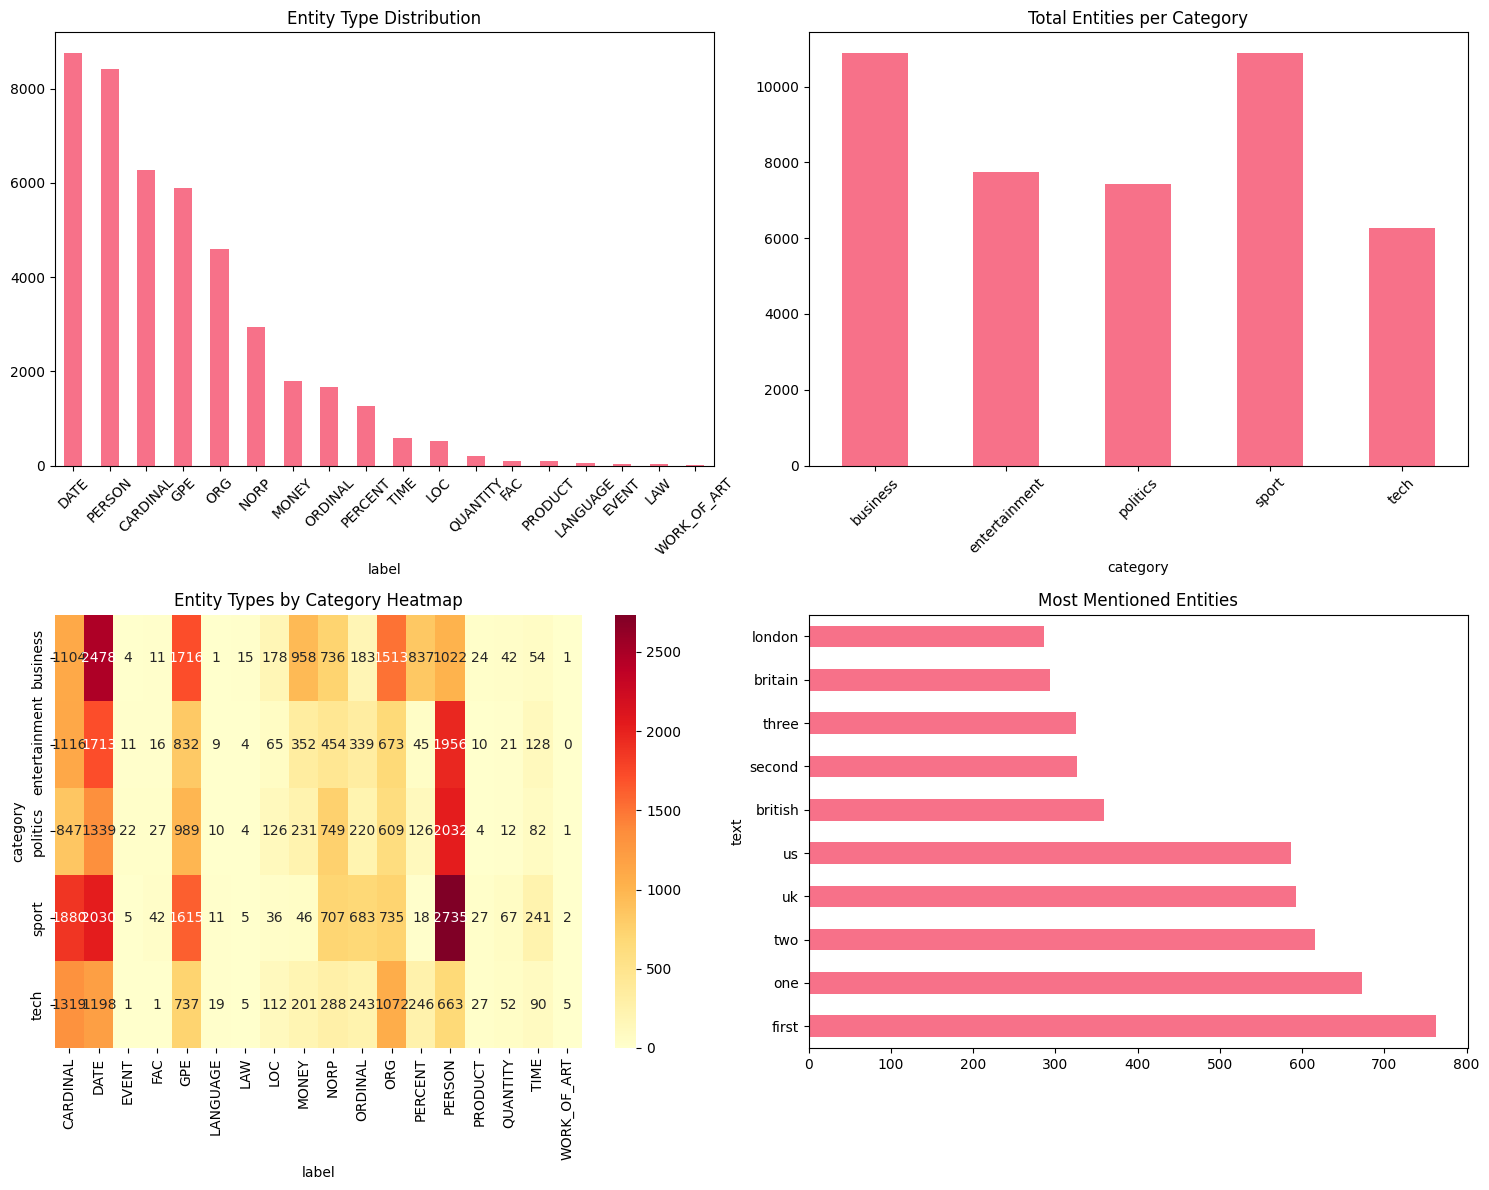

In [ ]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

In [ ]:
# Advanced Entity Analysis: Entity Sentiment Associations

# Get sentiment scores from Module 6
article_sentiment = sentiment_df[['article_id', 'full_sentiment']]

# Combine named entities with article sentiment
entity_sentiment = entities_df.merge(
    article_sentiment,
    on='article_id',
    how='left'
)

# Focus on people, organizations, and locations
entity_sentiment = entity_sentiment[
    entity_sentiment['label'].isin(['PERSON', 'ORG', 'GPE'])
].copy()

# Normalize entity names
entity_sentiment['text'] = (
    entity_sentiment['text'].str.lower().str.strip()
)

# Calculate average sentiment for each entity
sentiment_summary = entity_sentiment.groupby(
    ['text', 'label']
).agg(
    mentions=('full_sentiment', 'count'),
    avg_sentiment=('full_sentiment', 'mean')
).reset_index()

# Keep entities mentioned at least 10 times
sentiment_summary = sentiment_summary[
    sentiment_summary['mentions'] >= 10
]

# Show the most frequently mentioned entities
top_sentiment = sentiment_summary.sort_values(
    'mentions', ascending=False
).head(15)

print("Entity Sentiment Associations:")
print(top_sentiment.to_string(index=False))

Entity Sentiment Associations:
      text  label  mentions  avg_sentiment
        uk    GPE       593       0.438057
        us    GPE       587       0.241999
   britain    GPE       293       0.229267
    london    GPE       286       0.397352
    france    GPE       255       0.641631
       bbc    ORG       249       0.537014
     china    GPE       212       0.307933
   england    GPE       178       0.505486
     blair PERSON       167       0.197420
        eu PERSON       137       0.124490
     india    GPE       130       0.510862
tony blair PERSON       129       0.059404
 microsoft    ORG       127       0.458154
     japan    GPE       118       0.383078
      iraq    GPE       105       0.385390


I used the sentiment scores from Module 6 to analyze the relationship between named entities and sentiment. The results show that articles mentioning France have a higher average sentiment score of 0.642, while articles mentioning Tony Blair have a much lower score of 0.059. I also noticed that the UK and US were mentioned more frequently than many other entities. This experiment helped me understand how named entities can be connected with sentiment analysis. However, the sentiment scores represent the overall articles and do not necessarily show how people feel about a specific entity.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

  # Classification performance
  # I updated this section because the original code only used the
  # first model results from Module 7, which had lower accuracy.
  # After testing different features and tuning the C value,
  # my Logistic Regression model improved from 65.62% to 97.22%.
  # I changed the code to include my improved model and compare
  # it with the other models I tested.

    insights['classification_performance'] = {
        'best_model': 'Tuned Logistic Regression (TF-IDF)',
        'best_accuracy': tuned_accuracy,
        'model_comparison': {
        'Naive Bayes': results['Naive Bayes']['accuracy'],
        'Original Logistic Regression': results['Logistic Regression']['accuracy'],
        'SVM': results['SVM']['accuracy'],
        'TF-IDF Only': feature_results['TF-IDF Only'],
        'Tuned Logistic Regression': tuned_accuracy,
        'TF-IDF + POS': advanced_accuracy
    }
}

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1440
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2334 characters
  Average Words per Article: 402 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Tuned Logistic Regression (TF-IDF)
  Best Accuracy: 0.9722

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3793

🔍 ENTITY INSIGHTS:
  Total Entities: 43215
  Unique Entities: 12177
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - m

I combined the results from the previous modules to generate a comprehensive report of the news dataset. The dataset contains 1,440 articles across five different categories, with an average of 402 words per article. My best classification model was the tuned Logistic Regression model using TF-IDF, which achieved 97.22% accuracy. The sentiment analysis showed that entertainment articles had the highest average sentiment, while politics articles had the lowest. I also extracted 43,215 named entity mentions using spaCy. These results helped me understand how different NLP techniques can work together to analyze news articles and support automated content management.

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text


    def classify_article(self, processed_text):
    #"""Classify article category"""

    # I changed this because my best model from Module 7
    # was trained using TF-IDF features only.
    # The original code added 7 dummy features for sentiment
    # and length, which my tuned model does not use.

    # Transform the article using TF-IDF
      features = self.vectorizer.transform([processed_text])

    # Predict the news category
      prediction = self.classifier.predict(features)[0]

    # Get the probability for each category
      probabilities = self.classifier.predict_proba(features)[0]

    # Match each category with its probability
      class_probs = dict(zip(self.classifier.classes_, probabilities))

      return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [ ]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: business (42.96% confidence)

📊 Category Probabilities:
  business: 0.430
  tech: 0.175
  entertainment: 0.161
  politics: 0.120
  sport: 0.115

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment detected

## Test Anaylsis

 NewsBot successfully processed three different news articles and performed classification, sentiment analysis, and named entity recognition. One strength of the system is that it can analyze multiple parts of an article and provide useful information. However, I noticed that the system classified all three articles as Business. For test article 1, which was about Microsoft acquiring an AI startup, the model predicted Business. I think this article could belong to both Business and Technology, but I believe it is more likely to be Technology because it focuses on artificial intelligence. For test article 2, the model also predicted Business even though the article was about basketball and should have been classified as Sport. The confidence scores for all three articles were below 50%, showing that the model was uncertain about its predictions. Another weakness was that the named entity recognition system incorrectly identified some phrases as organizations. To improve the system, I could use the tuned Logistic Regression model from Module 7 and test it with more articles from different categories.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*